**Name:** Hrishikesh Nandkishor Koshti  
**PRN:** 202401040054  
**Div:** A  
**Roll No.:** A1-17

# AIML Assignment: Comparative Analysis of Classification Algorithms
## Dry Bean Classification Dataset

**Algorithms:** Support Vector Machine (SVM), Decision Tree (CART), K-Nearest Neighbors (KNN), Gaussian Naïve Bayes


## 1. Introduction

Classification is a supervised machine learning task in which a model learns from labelled examples and predicts the class of unseen observations. This experiment compares four commonly used classification algorithms on the Dry Bean dataset.

### Problem statement
Develop and compare SVM, Decision Tree (CART), KNN and Naïve Bayes classifiers to identify a dry bean variety from its geometrical measurements.

### Objectives
1. Inspect and prepare the dataset.
2. Explore the distribution and relationships of the input features.
3. Train four classification algorithms using a consistent experimental split.
4. Evaluate them with accuracy, macro precision, macro recall, macro F1-score and log loss.
5. Compare their performance, interpret their strengths and limitations, and discuss suitable use cases.

### Dataset overview
The commonly distributed Dry Bean dataset contains 13,611 observations, 16 numerical geometrical features and a target column named `Class`, with seven bean varieties. The downloaded file is checked in the notebook rather than assuming every copy has identical formatting.

## 2. Upload the Kaggle dataset manually

**Kaggle source:** [Dry Bean Dataset](https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset)

Download the dataset ZIP from Kaggle, extract it on your computer, and upload the contained `.xlsx`, `.xls` or `.csv` file using the upload prompt in the next code cell.

**This notebook does not connect to Kaggle, use KaggleHub, require an API token, or download the dataset automatically.** You are responsible for selecting and uploading the downloaded dataset file.

In [4]:
!pip -q install openpyxl

In [5]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, balanced_accuracy_score
)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

print("Libraries imported successfully.")

Libraries imported successfully.


In [6]:
# Upload the Dry Bean dataset file that you downloaded manually from Kaggle.
# Supported formats: .xlsx, .xls, and .csv
# No Kaggle API, KaggleHub, or automatic internet download is used.

from google.colab import files
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No dataset file was uploaded. Please download the Dry Bean dataset from Kaggle and upload it here.")

data_path = next(iter(uploaded.keys()))
print("Uploaded dataset:", data_path)
print("File size (bytes):", os.path.getsize(data_path))

Saving Dry_Bean_Dataset (1).xlsx to Dry_Bean_Dataset (1).xlsx
Uploaded dataset: Dry_Bean_Dataset (1).xlsx
File size (bytes): 3043104


In [7]:
# Read CSV or Excel, handling common Kaggle file formats.
extension = os.path.splitext(data_path)[1].lower()

if extension == ".csv":
    df = pd.read_csv(data_path)
elif extension in (".xlsx", ".xls"):
    df = pd.read_excel(data_path)
else:
    raise ValueError(f"Unsupported file format: {extension}. Please use CSV or Excel.")

# Standardize column names and remove accidental whitespace.
df.columns = [str(col).strip() for col in df.columns]

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:")
print(df.columns.tolist())

Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


\nColumn names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


## 3. Understand and validate the dataset

We inspect dimensions, data types, summary statistics, missing values, duplicates and the target column. The target is expected to be `Class`. The code handles minor naming variations such as `class` or `Class `.

In [8]:
# Identify target column robustly.
target_matches = [c for c in df.columns if c.strip().lower() == "class"]
if not target_matches:
    raise ValueError(
        "Could not identify the target column 'Class'. "
        "Please check the downloaded file's column names."
    )
TARGET = target_matches[0]

print("Target column:", TARGET)
print("\\nDataset information:")
df.info()

print("\\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())
print("\\nTarget class counts:")
display(df[TARGET].value_counts().to_frame("Count"))

Target column: Class
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class         

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Area,13611.0,NaN,NaN,NaN,53048.284549,29324.095717,20420.0,36328.0,44652.0,61332.0,254616.0
Perimeter,13611.0,NaN,NaN,NaN,855.283459,214.289696,524.736,703.5235,794.941,977.213,1985.37
MajorAxisLength,13611.0,NaN,NaN,NaN,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,NaN,NaN,NaN,202.270714,44.970091,122.512653,175.84817,192.431733,217.031741,460.198497
AspectRation,13611.0,NaN,NaN,NaN,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,NaN,NaN,NaN,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,NaN,NaN,NaN,53768.200206,29774.915817,20684.0,36714.5,45178.0,62294.0,263261.0
EquivDiameter,13611.0,NaN,NaN,NaN,253.06422,59.17712,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,NaN,NaN,NaN,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,NaN,NaN,NaN,0.987143,0.00466,0.919246,0.98567,0.988283,0.990013,0.994677


\nMissing values per column:


,Missing values
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Duplicate rows: 68
\nTarget class counts:


,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


## 4. Data cleaning and preprocessing

The original dataset is predominantly numerical and is commonly distributed without missing values. We still check these conditions in the downloaded copy.

- Exact duplicate rows are counted and removed, if present.
- Missing numerical values are imputed with the median inside each model pipeline. This keeps imputation fitted only on training folds.
- Any categorical predictor columns are one-hot encoded inside the pipeline.
- The target labels are encoded to integer values for modelling; the original class names are retained for reports and plots.
- Outliers are inspected with the IQR rule. They are not automatically deleted because extreme bean measurements may be genuine observations. Removing them without domain evidence could discard useful class information.

In [9]:
# Remove exact duplicate records, if any.
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows. Remaining rows: {len(df)}")

# Remove rows with missing target labels: target cannot be imputed reliably.
missing_target = df[TARGET].isna().sum()
if missing_target:
    df = df.dropna(subset=[TARGET]).reset_index(drop=True)
print("Rows removed due to missing target:", missing_target)

# Separate features and target.
X = df.drop(columns=[TARGET]).copy()
y_text = df[TARGET].astype(str).str.strip()

# Infer numerical and categorical predictors.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Target classes:", sorted(y_text.unique().tolist()))

# Encode target labels while preserving the class-name mapping.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = label_encoder.classes_
print("Class mapping:", {name: int(label_encoder.transform([name])[0]) for name in class_names})

Removed 68 duplicate rows. Remaining rows: 13543
Rows removed due to missing target: 0
Numerical features: 16
Categorical features: 0
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Class mapping: {'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}


In [10]:
# Missing-value and categorical checks.
print("Missing predictor values:", int(X.isna().sum().sum()))
if categorical_features:
    print("Categorical columns detected:", categorical_features)
    for col in categorical_features:
        print(f"\\n{col}:")
        display(X[col].value_counts(dropna=False).head(10))
else:
    print("No categorical predictor columns were found. No predictor encoding is required.")

Missing predictor values: 0
No categorical predictor columns were found. No predictor encoding is required.


## 5. Exploratory Data Analysis (EDA)

EDA helps understand class balance, feature distributions and relationships before model training. All plots below are generated from the actual downloaded dataset.

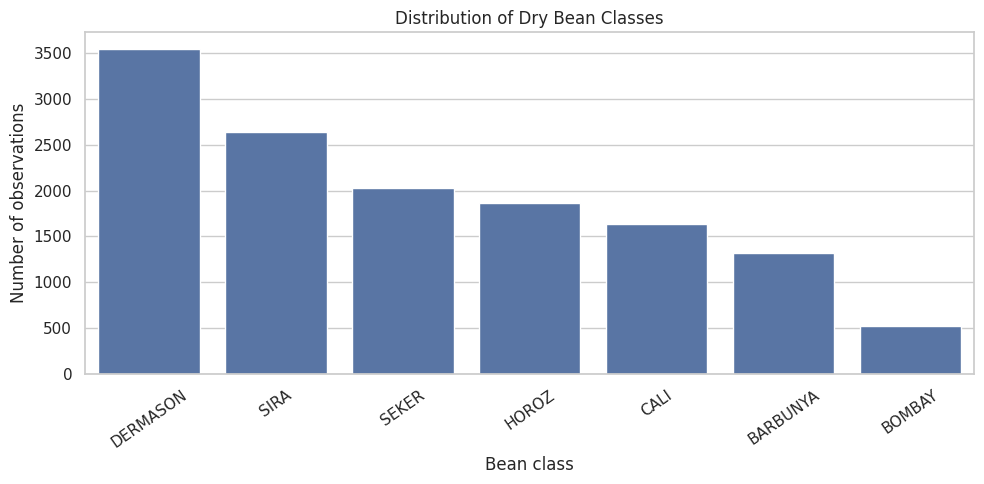

Class proportions (%):


,Percentage
Class,
DERMASON,26.18
SIRA,19.46
SEKER,14.97
HOROZ,13.73
CALI,12.04
BARBUNYA,9.76
BOMBAY,3.85


In [11]:
# Class distribution.
plt.figure(figsize=(10, 5))
order = y_text.value_counts().index
sns.countplot(data=pd.DataFrame({"Class": y_text}), x="Class", order=order)
plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean class")
plt.ylabel("Number of observations")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("Class proportions (%):")
display((y_text.value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

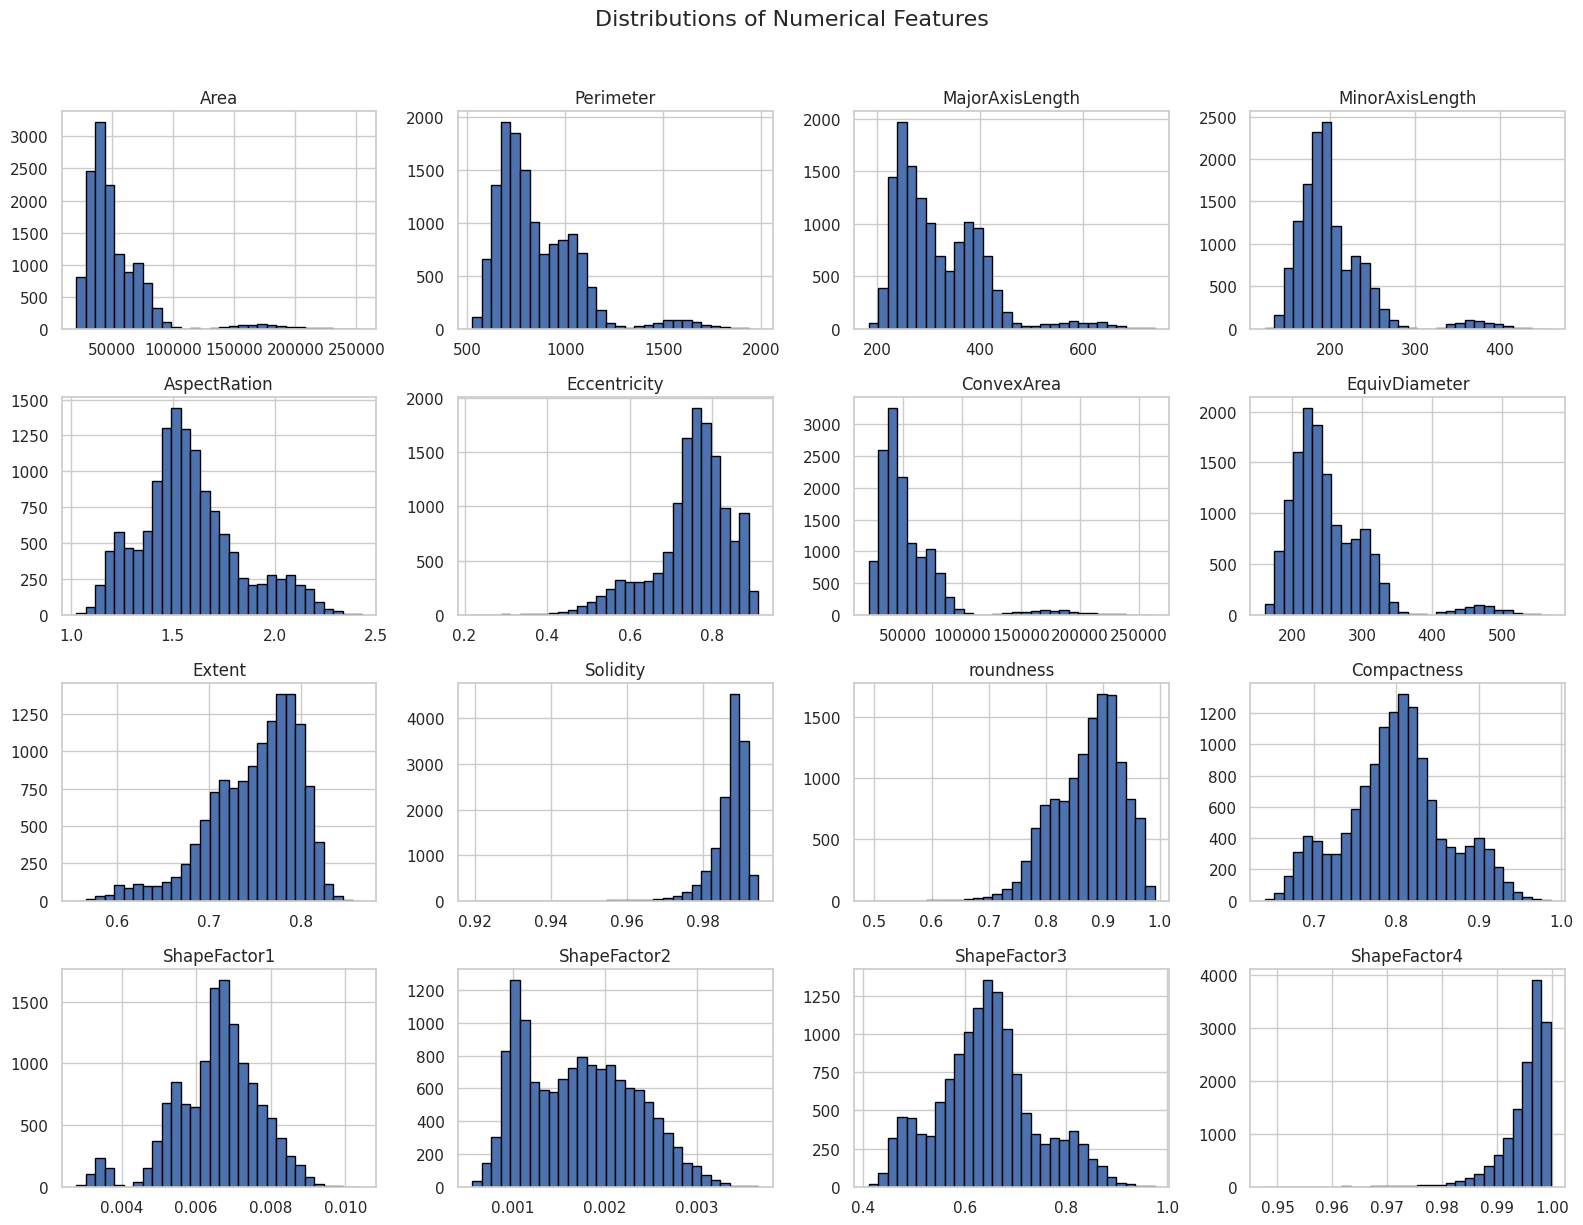

In [12]:
# Histograms of numerical features.
X[numeric_features].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Distributions of Numerical Features", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

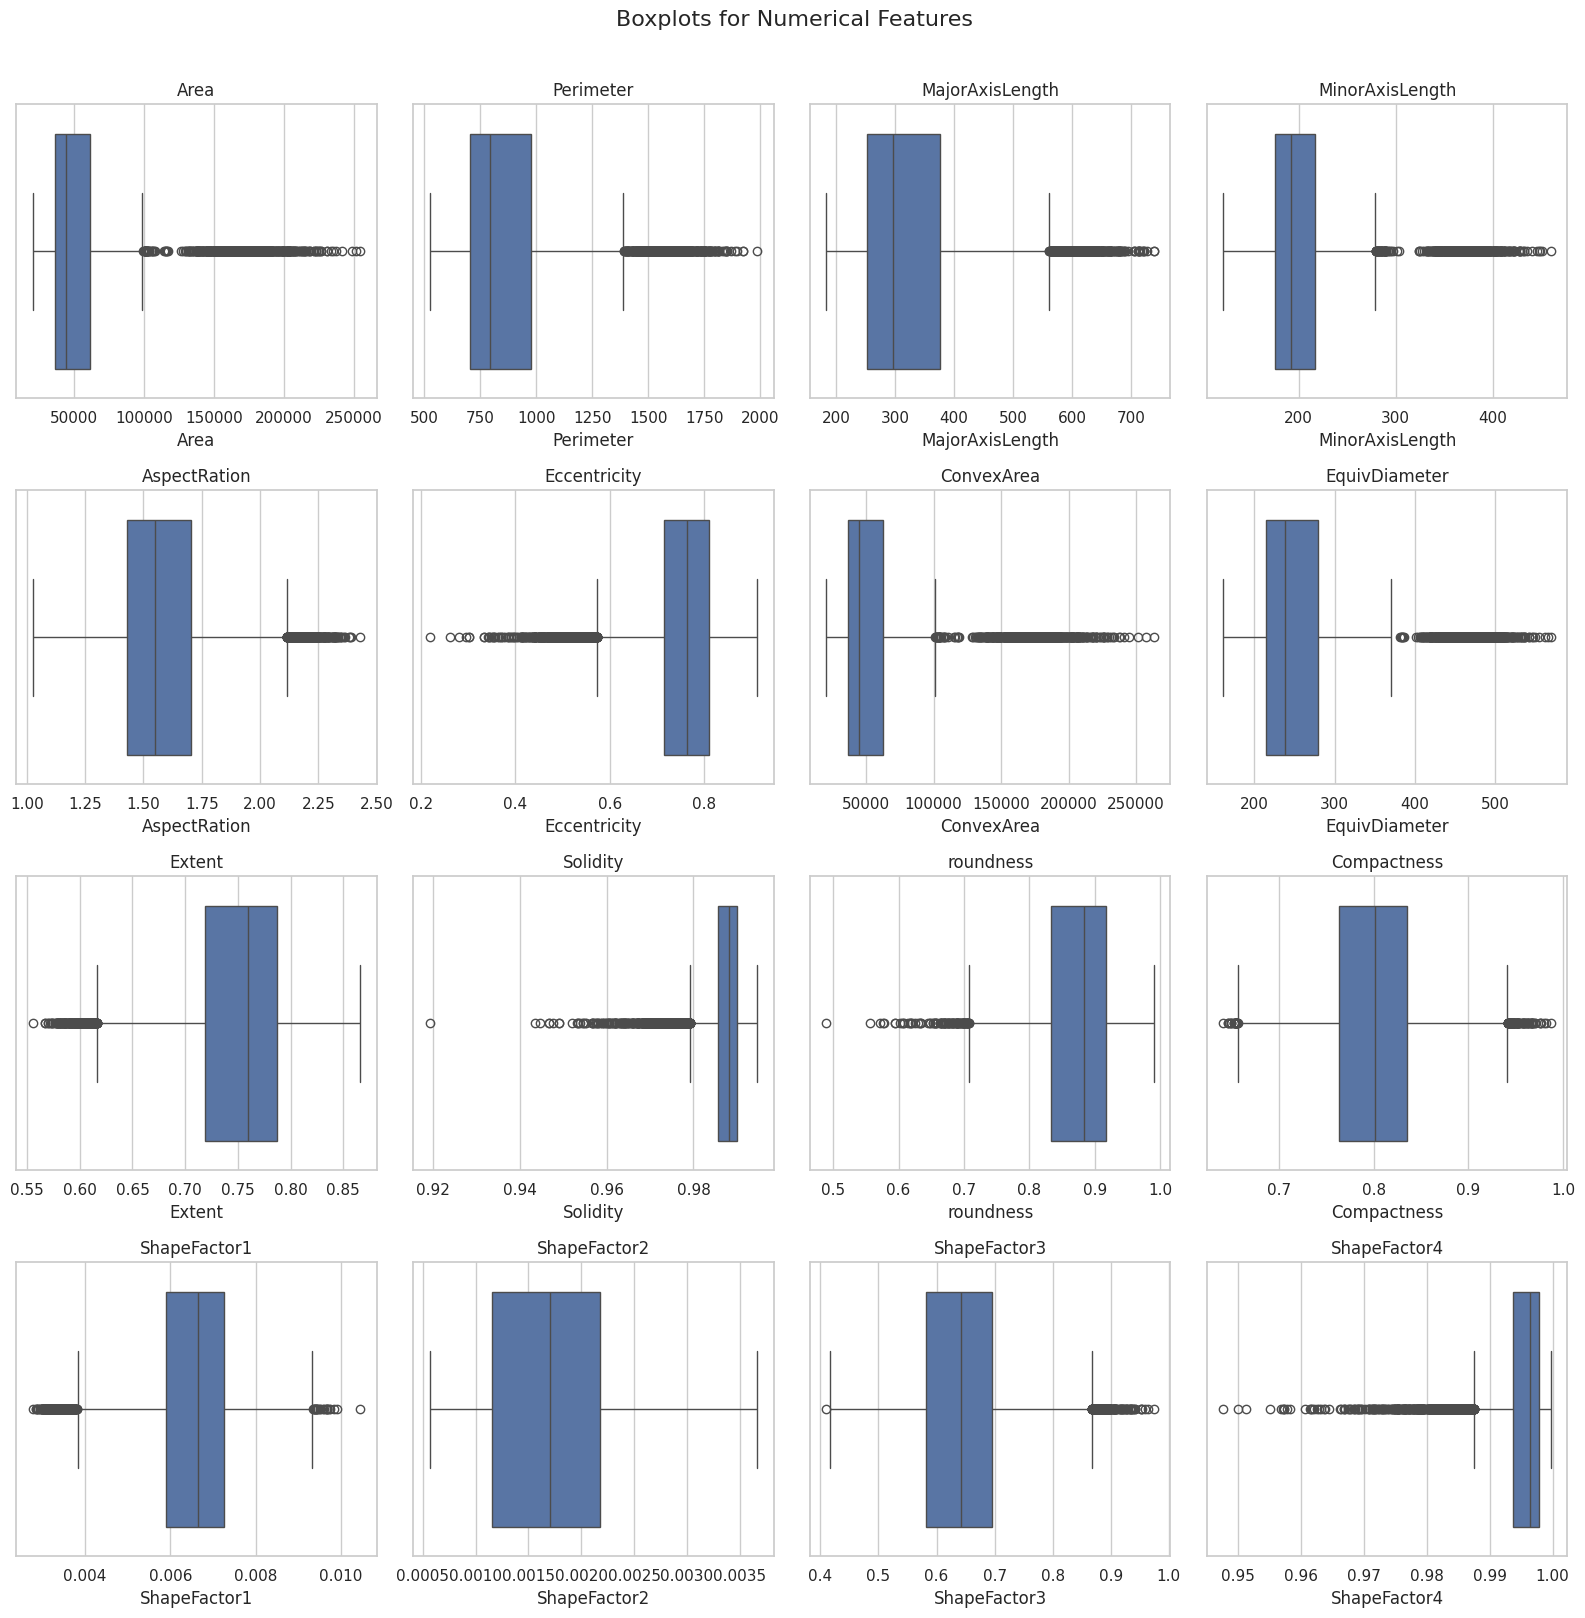

In [13]:
# Boxplots help identify potential outliers and differing feature scales.
n_cols = 4
n_rows = int(np.ceil(len(numeric_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_features):
    sns.boxplot(x=X[col], ax=ax)
    ax.set_title(col)
for ax in axes[len(numeric_features):]:
    ax.axis("off")

plt.suptitle("Boxplots for Numerical Features", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

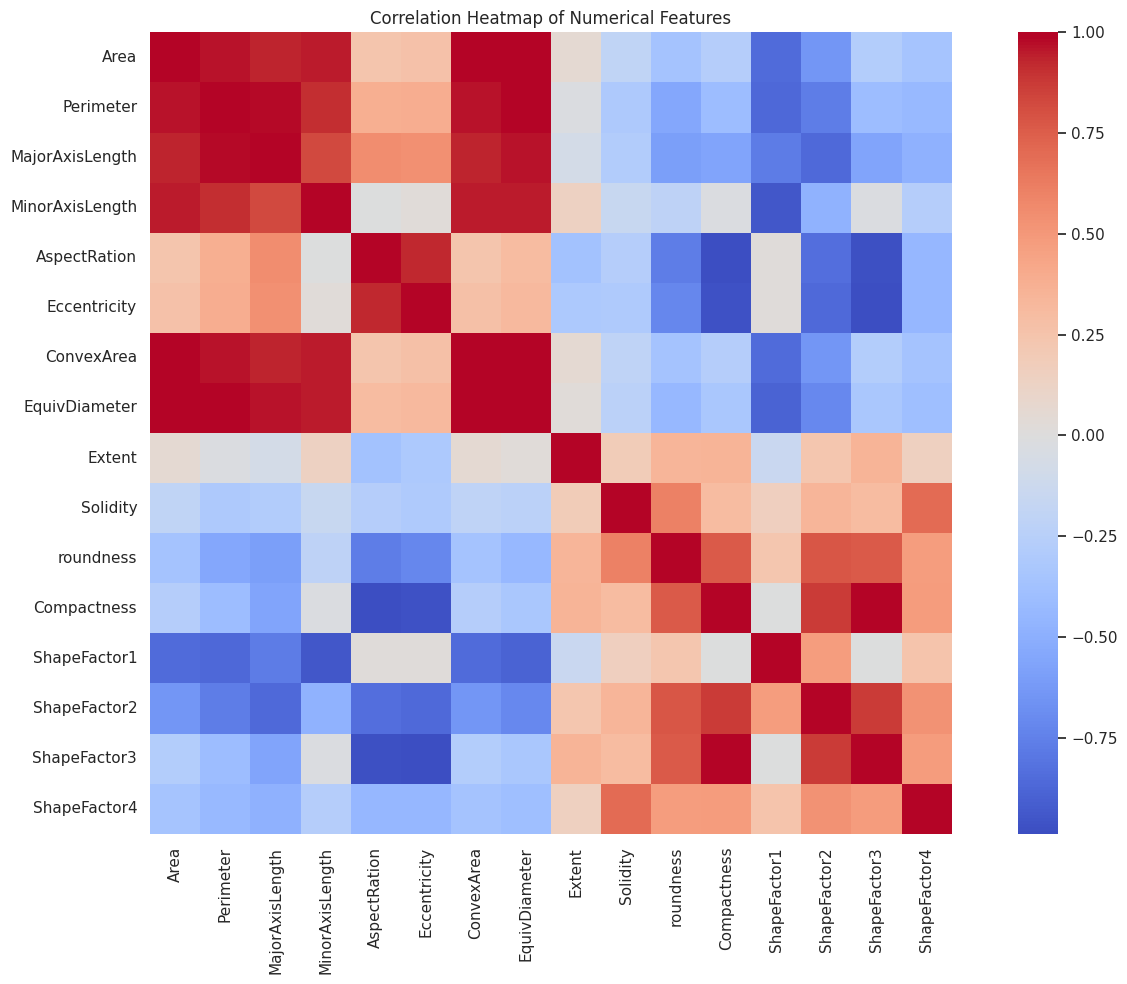

In [14]:
# Correlation heatmap.
if len(numeric_features) > 1:
    plt.figure(figsize=(14, 10))
    corr = X[numeric_features].corr()
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()

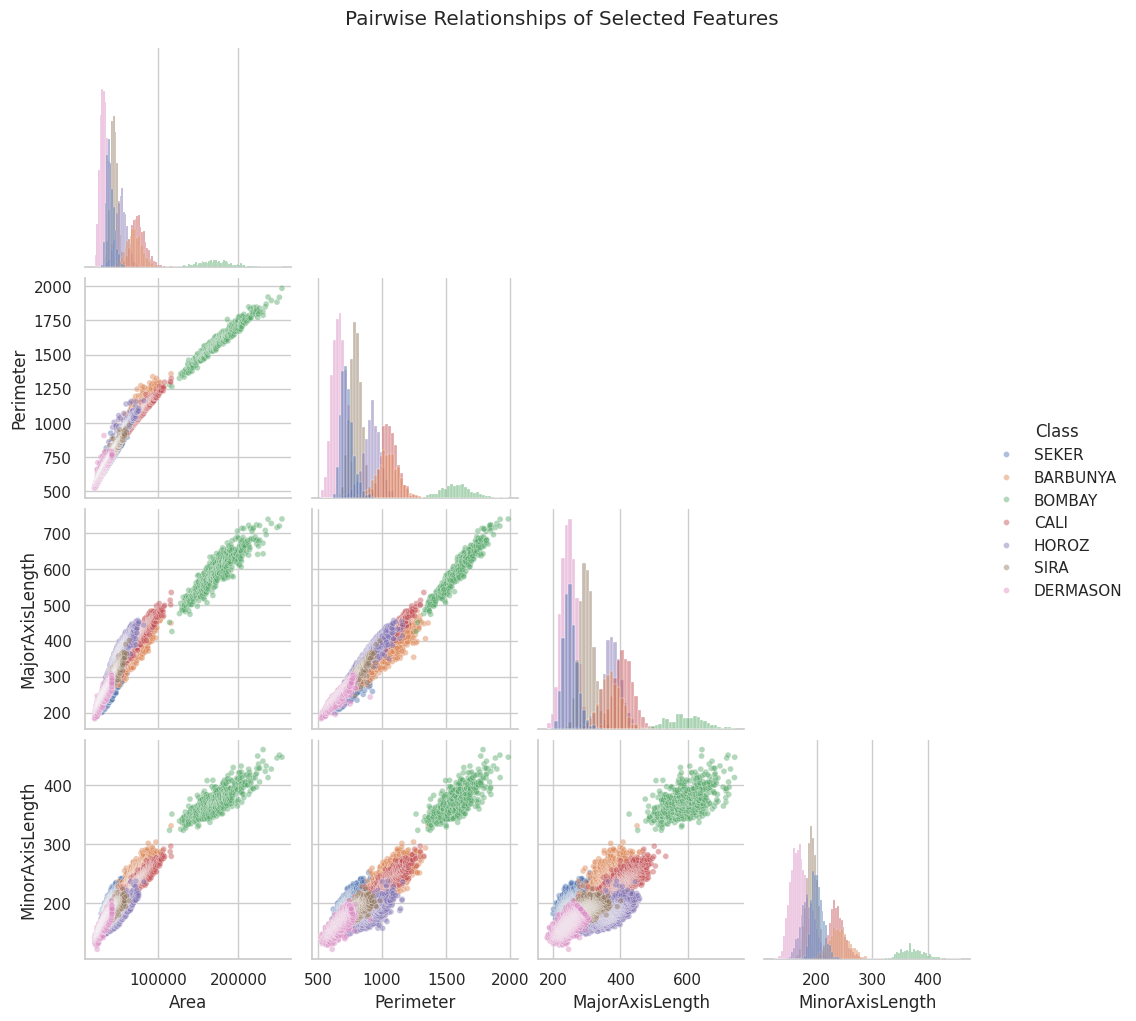

In [15]:
# Pairwise view of a small set of informative features to avoid an overcrowded plot.
candidate_features = [c for c in ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
                                  "AspectRation", "Eccentricity", "ConvexArea", "Extent"] if c in X.columns]
if len(candidate_features) >= 2:
    pair_df = X[candidate_features[:4]].copy()
    pair_df["Class"] = y_text.values
    sns.pairplot(pair_df, hue="Class", corner=True, diag_kind="hist",
                 plot_kws={"alpha": 0.45, "s": 18})
    plt.suptitle("Pairwise Relationships of Selected Features", y=1.02)
    plt.show()
else:
    print("Expected feature names were not found; pairplot skipped.")

## 6. Outlier analysis

The IQR method flags observations outside `[Q1 - 1.5 × IQR, Q3 + 1.5 × IQR]`. These are potential outliers, not necessarily errors. We report the number of flagged values per feature and retain the original observations for the main experiment unless a measurement error is established.

In [16]:
outlier_rows = []
for col in numeric_features:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((X[col] < lower) | (X[col] > upper)).sum())
    outlier_rows.append({
        "Feature": col, "Lower bound": lower, "Upper bound": upper,
        "Potential outlier count": count,
        "Potential outlier percentage": 100 * count / len(X)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "Potential outlier count", ascending=False
)
display(outlier_summary.round(3))
print("Decision: retain observations for the primary experiment; IQR flags alone do not prove invalid data.")

,Feature,Lower bound,Upper bound,Potential outlier count,Potential outlier percentage
5,Eccentricity,0.573,0.951,833,6.151
9,Solidity,0.979,0.997,774,5.715
15,ShapeFactor4,0.987,1.004,760,5.612
3,MinorAxisLength,113.848,279.284,567,4.187
0,Area,-1366.750,99031.250,551,4.069
6,ConvexArea,-1857.500,100890.500,549,4.054
12,ShapeFactor1,0.004,0.009,533,3.936
7,EquivDiameter,117.993,376.501,526,3.884
1,Perimeter,292.355,1388.021,500,3.692
4,AspectRation,1.021,2.114,485,3.581


Decision: retain observations for the primary experiment; IQR flags alone do not prove invalid data.


## 7. Train-test split and preprocessing pipelines

We use an 80:20 stratified split so that each bean variety is represented in both subsets. The test set is held out until final evaluation.

`StandardScaler` is used for SVM and KNN because both are sensitive to feature magnitudes. Gaussian Naïve Bayes is also placed in a consistent preprocessing pipeline. Decision Trees do not require scaling because their split decisions are based on feature thresholds; their pipeline uses imputation/encoding without scaling.

All imputers, encoders and scalers are fitted within pipelines during cross-validation, avoiding data leakage.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Training class proportions:")
display(pd.Series(label_encoder.inverse_transform(y_train)).value_counts(normalize=True).round(3).to_frame("Proportion"))
print("Testing class proportions:")
display(pd.Series(label_encoder.inverse_transform(y_test)).value_counts(normalize=True).round(3).to_frame("Proportion"))

# Preprocessing for scale-sensitive models.
numeric_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# If categorical predictors exist, impute and one-hot encode them.
from sklearn.preprocessing import OneHotEncoder

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # Compatibility with older scikit-learn versions
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_encoded = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

scaled_transformers = [("num", numeric_scaled, numeric_features)]
if categorical_features:
    scaled_transformers.append(("cat", categorical_encoded, categorical_features))

scaled_preprocessor = ColumnTransformer(transformers=scaled_transformers)

# Decision Tree preprocessing does not scale numerical measurements.
numeric_unscaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
unscaled_transformers = [("num", numeric_unscaled, numeric_features)]
if categorical_features:
    unscaled_transformers.append(("cat", categorical_encoded, categorical_features))

tree_preprocessor = ColumnTransformer(transformers=unscaled_transformers)

print("Preprocessing pipelines created.")

Training records: 10834
Testing records: 2709
Training class proportions:


,Proportion
DERMASON,0.262
SIRA,0.195
SEKER,0.150
HOROZ,0.137
CALI,0.120
BARBUNYA,0.098
BOMBAY,0.039


Testing class proportions:


,Proportion
DERMASON,0.262
SIRA,0.195
SEKER,0.150
HOROZ,0.137
CALI,0.120
BARBUNYA,0.098
BOMBAY,0.038


Preprocessing pipelines created.


## 8. Model implementation and hyperparameter tuning

The four required algorithms are implemented below. `GridSearchCV` uses 5-fold stratified cross-validation and macro F1 as the selection metric, giving each of the seven classes equal weight. The held-out test set is not used for parameter selection.

The grids are intentionally compact so the notebook remains practical to run in Google Colab. The SVM uses an RBF kernel and probability estimates to support log-loss calculation.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_configs = {
    "SVM": {
        "pipeline": Pipeline(steps=[
            ("preprocess", scaled_preprocessor),
            ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
        ]),
        "params": {
            "classifier__C": [1, 10],
            "classifier__gamma": ["scale", 0.01]
        }
    },
    "Decision Tree (CART)": {
        "pipeline": Pipeline(steps=[
            ("preprocess", tree_preprocessor),
            ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE, criterion="gini"))
        ]),
        "params": {
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_leaf": [1, 3],
            "classifier__min_samples_split": [2, 5]
        }
    },
    "KNN": {
        "pipeline": Pipeline(steps=[
            ("preprocess", scaled_preprocessor),
            ("classifier", KNeighborsClassifier())
        ]),
        "params": {
            "classifier__n_neighbors": [5, 9, 15],
            "classifier__weights": ["uniform", "distance"],
            "classifier__p": [1, 2]
        }
    },
    "Gaussian Naive Bayes": {
        "pipeline": Pipeline(steps=[
            ("preprocess", scaled_preprocessor),
            ("classifier", GaussianNB())
        ]),
        "params": {
            "classifier__var_smoothing": [1e-9, 1e-8, 1e-7]
        }
    }
}

searches = {}
best_models = {}

for model_name, config in model_configs.items():
    print(f"\\nTuning {model_name} ...")
    search = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=config["params"],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
        pre_dispatch="2*n_jobs"
    )
    search.fit(X_train, y_train)
    searches[model_name] = search
    best_models[model_name] = search.best_estimator_
    print("Best CV macro F1:", round(search.best_score_, 5))
    print("Best parameters:", search.best_params_)

print("\\nAll four models have been tuned.")

\nTuning SVM ...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best CV macro F1: 0.94376
Best parameters: {'classifier__C': 10, 'classifier__gamma': 'scale'}
\nTuning Decision Tree (CART) ...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV macro F1: 0.92208
Best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 3, 'classifier__min_samples_split': 2}
\nTuning KNN ...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV macro F1: 0.93712
Best parameters: {'classifier__n_neighbors': 15, 'classifier__p': 2, 'classifier__weights': 'distance'}
\nTuning Gaussian Naive Bayes ...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best CV macro F1: 0.90641
Best parameters: {'classifier__var_smoothing': 1e-09}
\nAll four models have been tuned.


## 9. Training and evaluation

Each tuned model is evaluated on the same unseen test set. We report accuracy, macro precision, macro recall, macro F1-score, balanced accuracy and multiclass log loss.

Log loss requires class probabilities. SVM is configured with `probability=True`; the other selected estimators also provide `predict_proba`. Lower log loss is better. Macro averages treat each class equally, which is useful when class frequencies differ.

In [19]:
results = []
test_predictions = {}
test_probabilities = {}
train_probabilities = {}

for model_name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    # Training log loss is included as a diagnostic, not as an unbiased estimate.
    y_train_prob = model.predict_proba(X_train)

    test_predictions[model_name] = y_pred
    test_probabilities[model_name] = y_prob
    train_probabilities[model_name] = y_train_prob

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Test Log Loss": log_loss(y_test, y_prob, labels=np.arange(len(class_names))),
        "Train Log Loss": log_loss(y_train, y_train_prob, labels=np.arange(len(class_names))),
        "Best CV Macro F1": searches[model_name].best_score_
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values(
    "F1-score (Macro)", ascending=False
)
display(results_df.round(4))

,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Balanced Accuracy,Test Log Loss,Train Log Loss,Best CV Macro F1
Model,,,,,,,,
SVM,0.9236,0.9356,0.9340,0.9347,0.9340,0.2118,0.1711,0.9438
KNN,0.9155,0.9302,0.9265,0.9279,0.9265,0.5610,0.0000,0.9371
Decision Tree (CART),0.9029,0.9174,0.9173,0.9172,0.9173,1.3643,0.1267,0.9221
Gaussian Naive Bayes,0.8970,0.9081,0.9082,0.9072,0.9082,0.9866,0.9523,0.9064


In [20]:
# Classification report for each model.
for model_name, y_pred in test_predictions.items():
    print("\\n" + "=" * 75)
    print(model_name)
    print("=" * 75)
    print(classification_report(
        y_test, y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

\n===========================================================================
SVM
              precision    recall  f1-score   support

    BARBUNYA     0.9237    0.9132    0.9184       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9245    0.9387    0.9315       326
    DERMASON     0.9148    0.9238    0.9193       709
       HOROZ     0.9694    0.9382    0.9536       372
       SEKER     0.9439    0.9532    0.9485       406
        SIRA     0.8726    0.8710    0.8718       527

    accuracy                         0.9236      2709
   macro avg     0.9356    0.9340    0.9347      2709
weighted avg     0.9238    0.9236    0.9236      2709

\n===========================================================================
Decision Tree (CART)
              precision    recall  f1-score   support

    BARBUNYA     0.9115    0.8943    0.9029       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.8941    0.9325    0.9129       326
    D

## 10. Confusion matrices

A confusion matrix shows the number of correct and incorrect predictions for every class. The diagonal represents correct predictions; off-diagonal cells show which bean varieties are being confused.

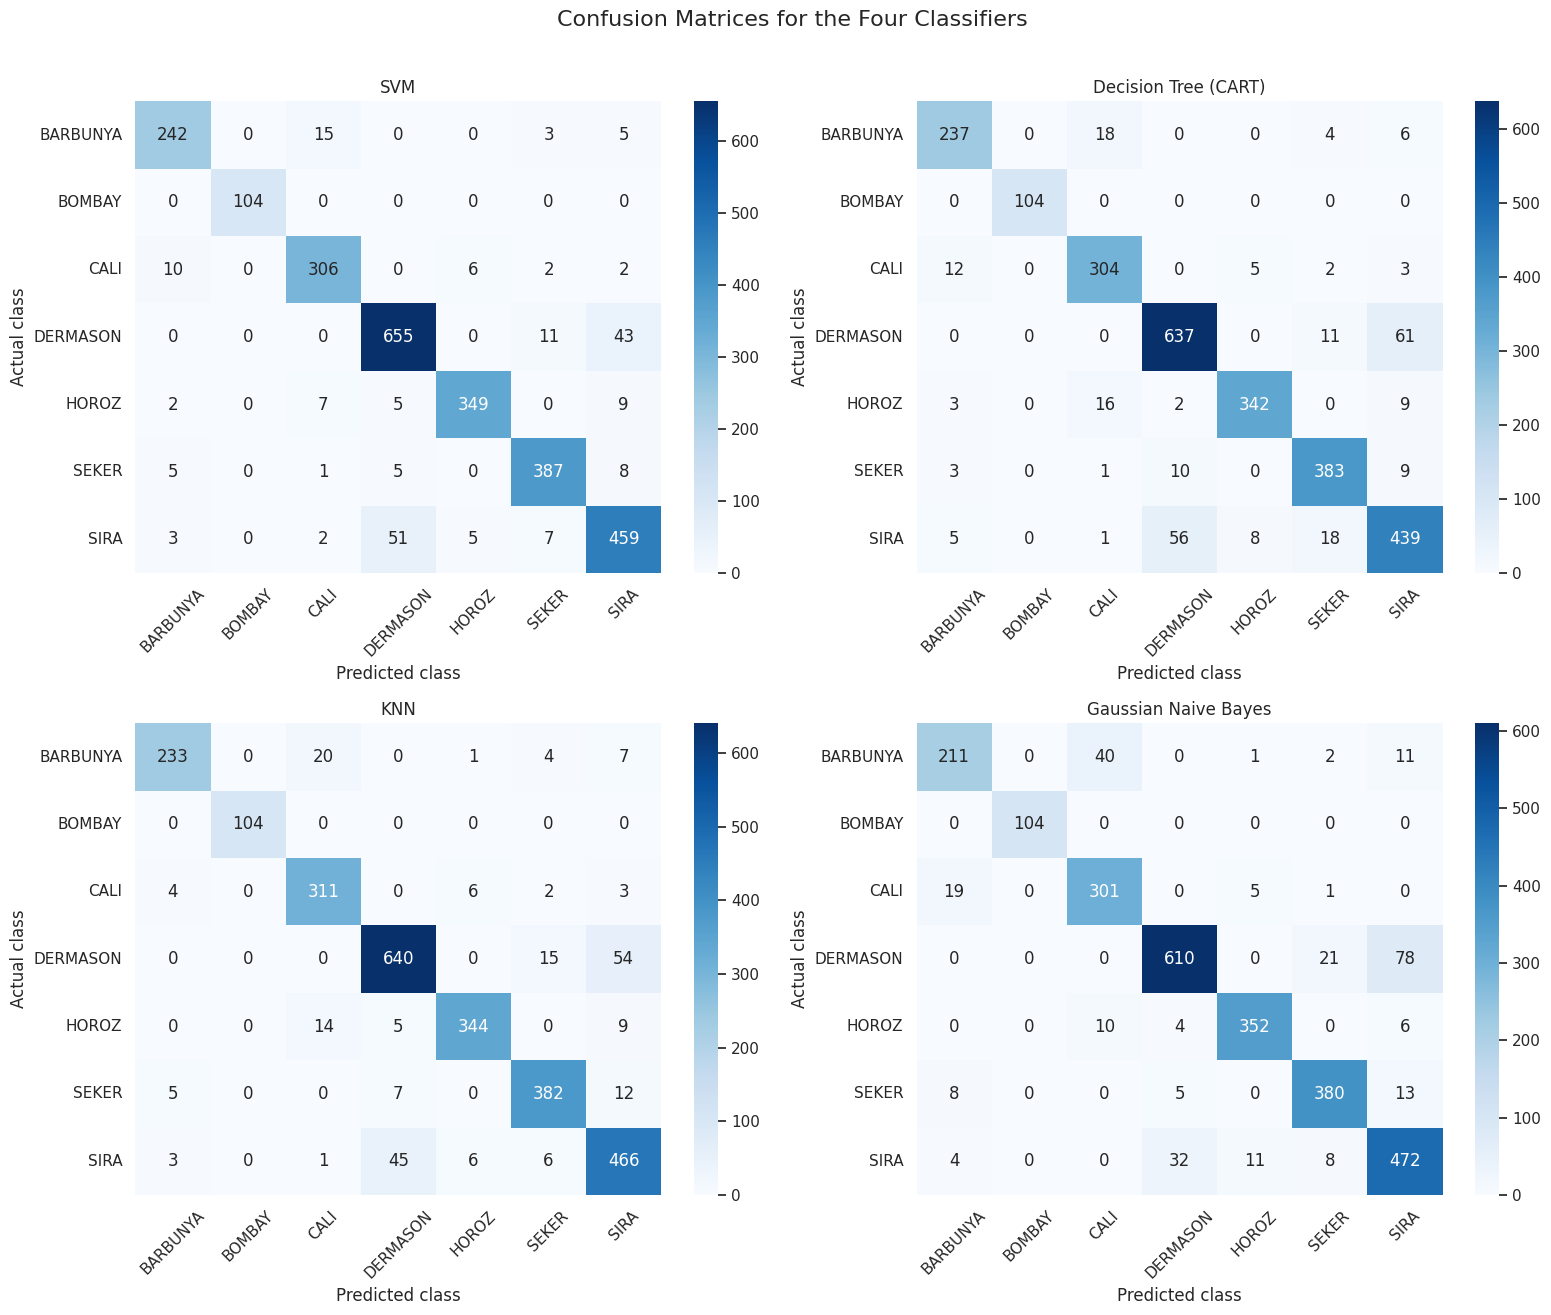

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.ravel()

for ax, (model_name, y_pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrices for the Four Classifiers", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## 11. Comparative analysis and visualization

The following charts compare the actual test-set metrics. No performance values are hard-coded. The notebook identifies the leading model by macro F1-score and separately reports the model with the lowest log loss.

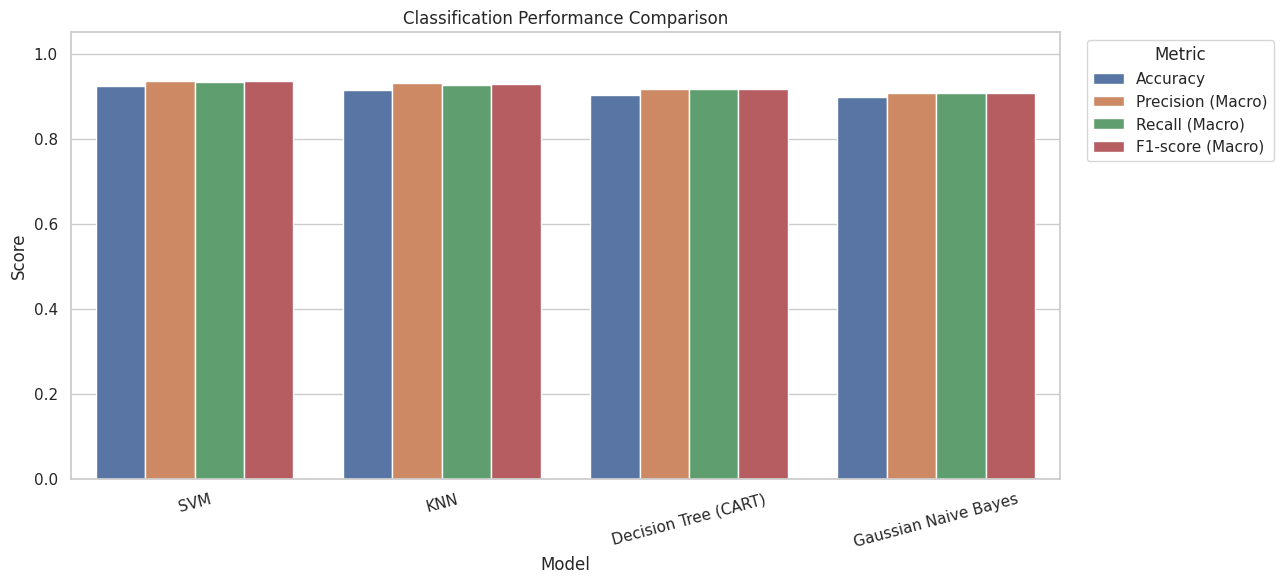

In [22]:
# Compare the principal classification metrics.
metric_cols = ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-score (Macro)"]
plot_df = results_df[metric_cols].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score"
)

plt.figure(figsize=(13, 6))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05)
plt.title("Classification Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

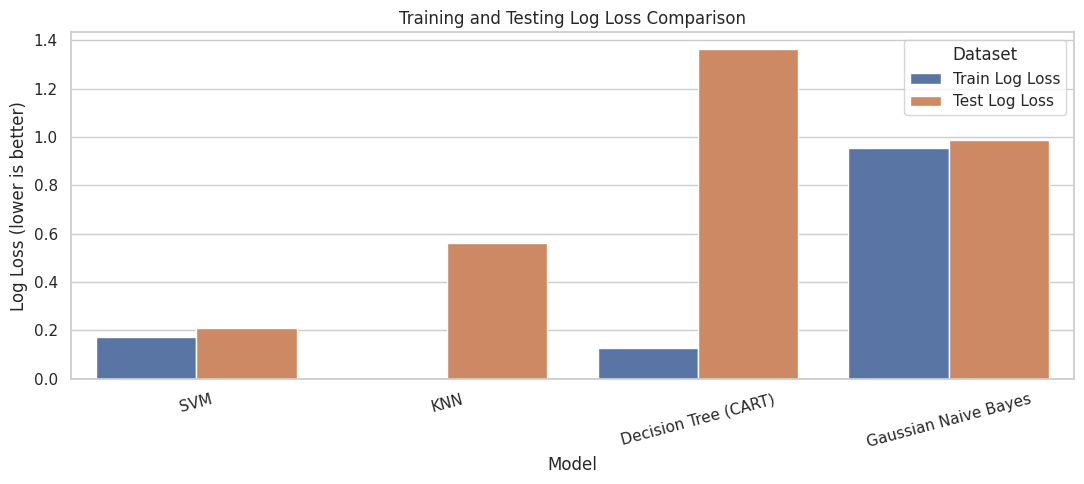

In [23]:
# Compare log loss. Lower values indicate better probability estimates.
loss_plot = results_df[["Train Log Loss", "Test Log Loss"]].reset_index().melt(
    id_vars="Model", var_name="Dataset", value_name="Log Loss"
)

plt.figure(figsize=(11, 5))
sns.barplot(data=loss_plot, x="Model", y="Log Loss", hue="Dataset")
plt.title("Training and Testing Log Loss Comparison")
plt.ylabel("Log Loss (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

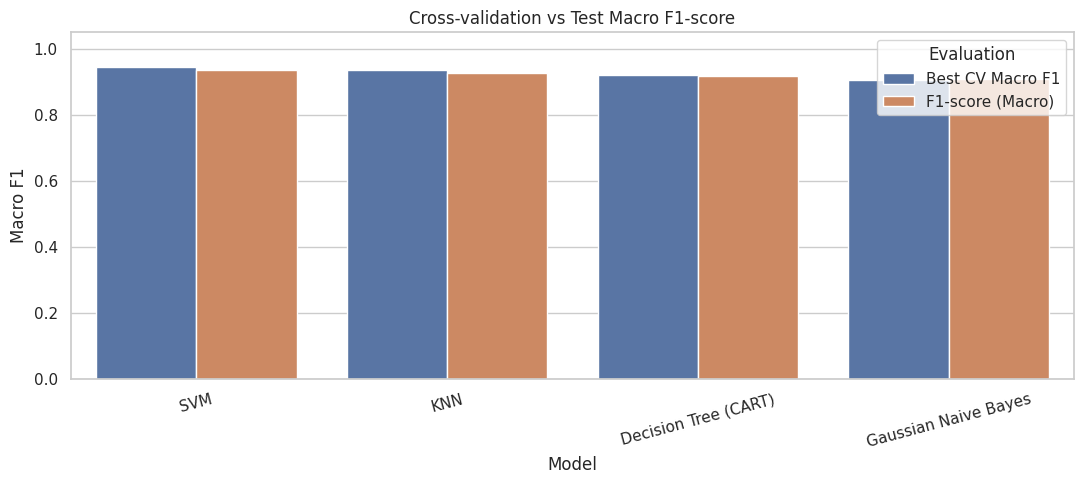

In [24]:
# Cross-validation macro F1 compared with held-out test macro F1.
cv_test = results_df[["Best CV Macro F1", "F1-score (Macro)"]].reset_index().melt(
    id_vars="Model", var_name="Evaluation", value_name="Macro F1"
)
plt.figure(figsize=(11, 5))
sns.barplot(data=cv_test, x="Model", y="Macro F1", hue="Evaluation")
plt.ylim(0, 1.05)
plt.title("Cross-validation vs Test Macro F1-score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 12. Model interpretation

A Decision Tree can provide human-readable decision rules and feature importance. Feature importance is model-specific and should not be interpreted as causal evidence.

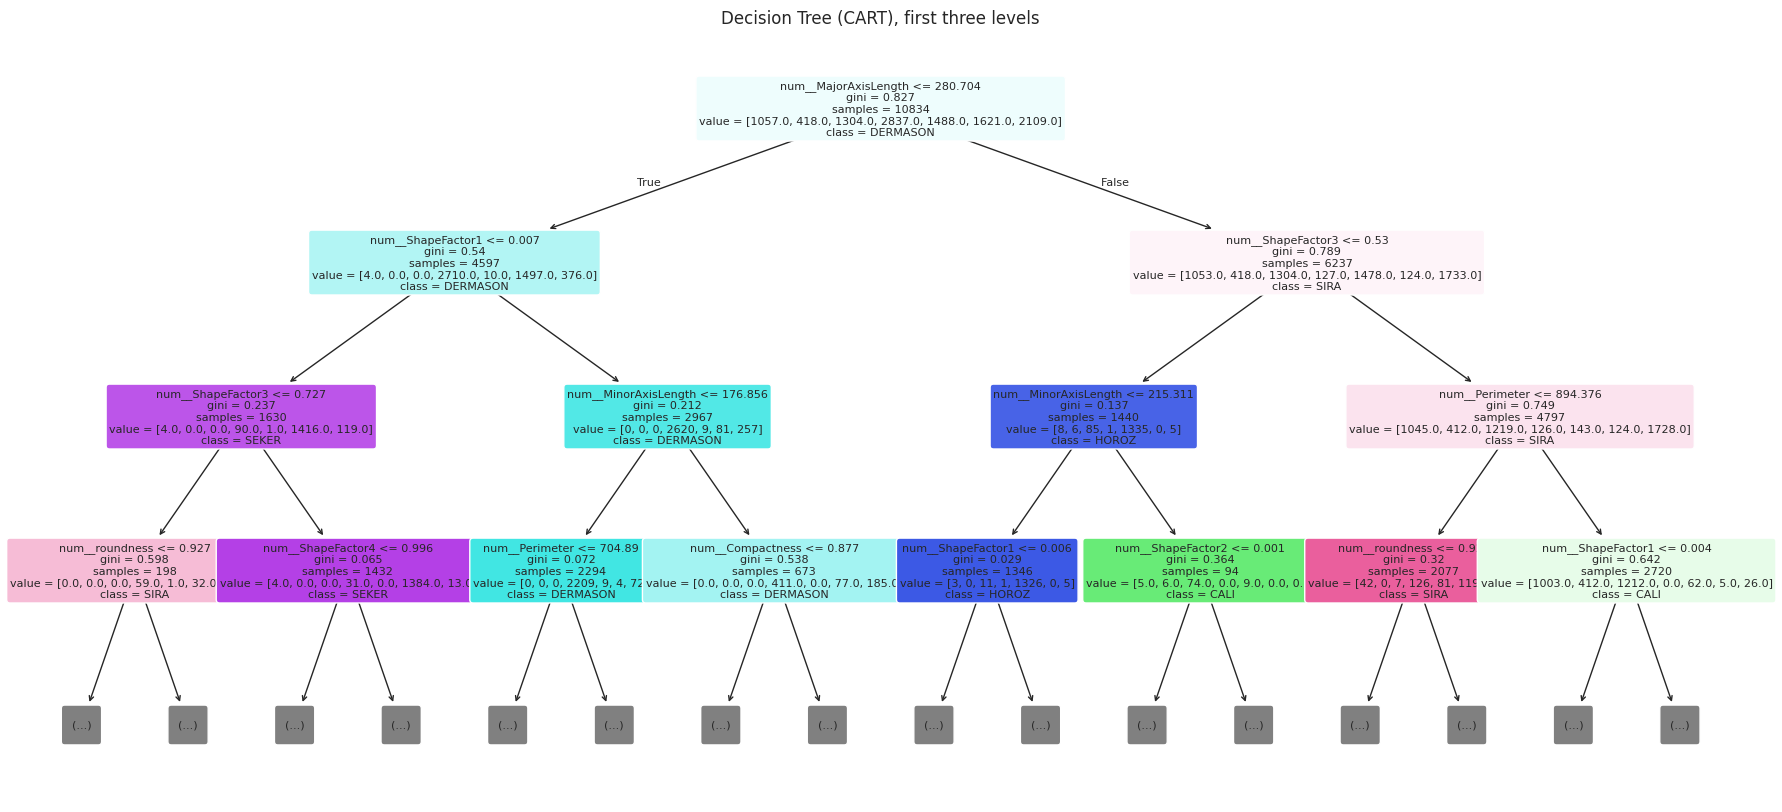

,Feature,Importance
12,num__ShapeFactor1,0.243995
14,num__ShapeFactor3,0.222130
2,num__MajorAxisLength,0.193269
1,num__Perimeter,0.159058
10,num__roundness,0.070054
3,num__MinorAxisLength,0.031979
11,num__Compactness,0.022432
15,num__ShapeFactor4,0.019395
9,num__Solidity,0.014151
7,num__EquivDiameter,0.008413


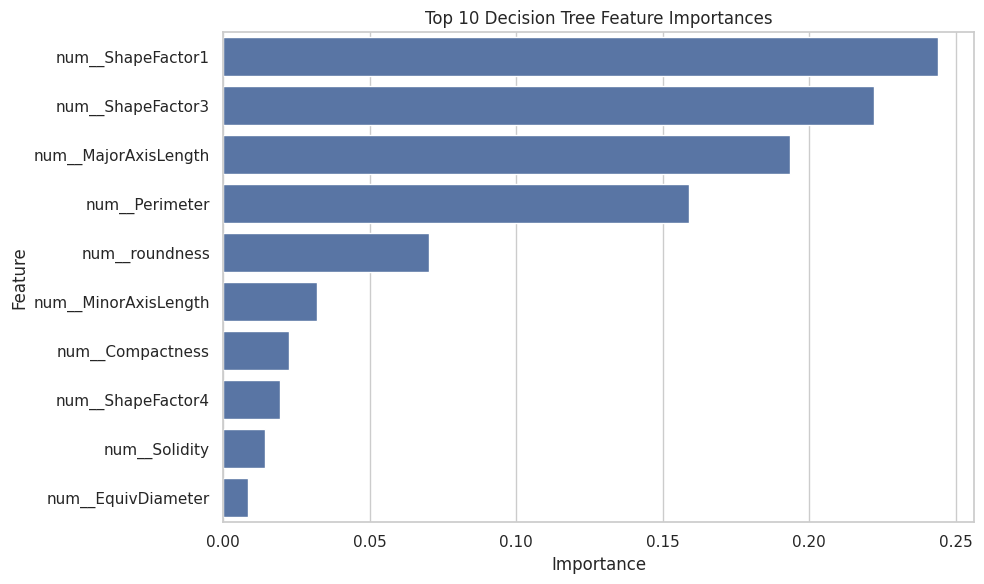

In [25]:
# Plot the tuned CART tree. Limit displayed depth for readability.
tree_model = best_models["Decision Tree (CART)"]
tree_classifier = tree_model.named_steps["classifier"]

try:
    transformed_feature_names = tree_model.named_steps["preprocess"].get_feature_names_out()
except Exception:
    transformed_feature_names = [f"Feature {i}" for i in range(tree_classifier.n_features_in_)]

plt.figure(figsize=(22, 10))
plot_tree(
    tree_classifier,
    feature_names=transformed_feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (CART), first three levels")
plt.show()

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": tree_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(10), x="Importance", y="Feature")
plt.title("Top 10 Decision Tree Feature Importances")
plt.tight_layout()
plt.show()

## 13. Critical discussion: suitability of each algorithm

Use the measured results above when completing this discussion. The points below describe general algorithm properties; the final ranking must be based on this experiment's outputs.

| Algorithm | Strengths | Limitations | Suitable situations |
|---|---|---|---|
| SVM | Can model complex boundaries with kernels; effective in high-dimensional feature spaces | Requires scaling; parameter and kernel selection matter; probability estimates add computation | Medium-sized datasets with clear margins or nonlinear boundaries |
| Decision Tree (CART) | Interpretable rules; handles nonlinear relationships; little preprocessing; no scaling required | Can overfit; small data changes can alter the tree | Explainable decisions, rule extraction and mixed feature interactions |
| KNN | Simple, non-parametric and can model local nonlinear boundaries | Prediction can be slow; sensitive to scaling, noise and choice of K | Smaller datasets where similar observations have similar labels |
| Gaussian Naïve Bayes | Fast training and prediction; naturally probabilistic; simple baseline | Assumes conditional independence and Gaussian feature distributions | Fast baselines and tasks where its distribution assumptions are reasonable |

### Questions to answer using the observed results
1. Which model has the highest test accuracy?
2. Which model has the highest macro F1-score?
3. Which model has the lowest test log loss?
4. Are any models showing a large difference between training and test log loss?
5. Which classes have the most confusion, according to the confusion matrices?
6. Does the best cross-validation model also perform best on the held-out test set?
7. Which algorithm offers the best balance of predictive performance, interpretability and computational cost?

In [26]:
# Generate evidence-based summary statements from the actual results.
best_f1_model = results_df["F1-score (Macro)"].idxmax()
best_accuracy_model = results_df["Accuracy"].idxmax()
best_logloss_model = results_df["Test Log Loss"].idxmin()

print("BEST MODEL BY MACRO F1:", best_f1_model)
print("Macro F1:", round(results_df.loc[best_f1_model, "F1-score (Macro)"], 4))
print("\\nBEST MODEL BY ACCURACY:", best_accuracy_model)
print("Accuracy:", round(results_df.loc[best_accuracy_model, "Accuracy"], 4))
print("\\nBEST MODEL BY LOWEST TEST LOG LOSS:", best_logloss_model)
print("Test log loss:", round(results_df.loc[best_logloss_model, "Test Log Loss"], 4))

print("\\nOVERALL TEST METRIC RANKING (higher is better except log loss):")
display(results_df.round(4))

BEST MODEL BY MACRO F1: SVM
Macro F1: 0.9347
\nBEST MODEL BY ACCURACY: SVM
Accuracy: 0.9236
\nBEST MODEL BY LOWEST TEST LOG LOSS: SVM
Test log loss: 0.2118
\nOVERALL TEST METRIC RANKING (higher is better except log loss):


,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Balanced Accuracy,Test Log Loss,Train Log Loss,Best CV Macro F1
Model,,,,,,,,
SVM,0.9236,0.9356,0.9340,0.9347,0.9340,0.2118,0.1711,0.9438
KNN,0.9155,0.9302,0.9265,0.9279,0.9265,0.5610,0.0000,0.9371
Decision Tree (CART),0.9029,0.9174,0.9173,0.9172,0.9173,1.3643,0.1267,0.9221
Gaussian Naive Bayes,0.8970,0.9081,0.9082,0.9072,0.9082,0.9866,0.9523,0.9064


## 14. Conclusion

Complete this section after running all cells. Replace the bracketed prompts with the actual values printed in Section 13.

This experiment compared Support Vector Machine, Decision Tree (CART), K-Nearest Neighbors and Gaussian Naïve Bayes for classifying seven dry bean varieties using geometrical measurements. The dataset was inspected, cleaned where necessary, explored through statistical summaries and visualizations, and split into stratified training and testing subsets. Preprocessing was implemented inside pipelines to prevent information from the test set leaking into training.

According to the measured results, **[model]** achieved the highest macro F1-score of **[value]**, while **[model]** achieved the highest accuracy of **[value]**. The lowest test log loss was achieved by **[model]**, with a value of **[value]**. These results show that model selection should consider class-wise performance and probability quality, not accuracy alone.

SVM is useful when a suitable decision boundary can separate classes, KNN is useful when local similarity is informative, CART is valuable when interpretable rules are important, and Gaussian Naïve Bayes is useful when a fast probabilistic baseline is needed and its assumptions are reasonably satisfied. The most suitable algorithm depends on the observed metrics, interpretability requirements, dataset size and deployment constraints.

### Limitations and future improvements
- The experiment uses one dataset and one held-out test split.
- Grid-search results depend on the selected parameter ranges.
- IQR outlier flags were inspected but not automatically removed.
- Further work could test repeated stratified cross-validation, calibrated probabilities, feature selection, alternative kernels and more extensive parameter searches.
- Results from this dataset should not be generalized to all agricultural classification tasks without testing on independent data.

## 15. Ethical considerations

This dataset contains measurements of bean specimens rather than personal data. Nevertheless, responsible use requires:
- Reporting class-wise performance rather than relying only on overall accuracy.
- Avoiding unsupported claims that a model will work equally well across farms, imaging devices or bean-growing regions.
- Checking data provenance and documenting preprocessing choices.
- Treating model predictions as decision support, with human verification in practical agricultural settings.
- Disclosing limitations and avoiding fabricated or selectively reported results.

## 16. Export results and processed data

This section saves the comparison table, classification reports and cleaned dataset so they can be downloaded and included in the assignment submission.

In [27]:
# Save comparison metrics.
results_df.to_csv("dry_bean_model_comparison.csv")

# Save the cleaned dataset used for the experiment (target retained).
df.to_csv("dry_bean_cleaned_dataset.csv", index=False)

# Save detailed per-class reports.
report_frames = []
for model_name, y_pred in test_predictions.items():
    report_dict = classification_report(
        y_test, y_pred, target_names=class_names,
        output_dict=True, zero_division=0
    )
    report_df = pd.DataFrame(report_dict).T
    report_df["Model"] = model_name
    report_frames.append(report_df.reset_index(names="Class_or_metric"))

all_reports = pd.concat(report_frames, ignore_index=True)
all_reports.to_csv("dry_bean_classification_reports.csv", index=False)

print("Files created:")
print("- dry_bean_model_comparison.csv")
print("- dry_bean_cleaned_dataset.csv")
print("- dry_bean_classification_reports.csv")

display(results_df.round(4))

Files created:
- dry_bean_model_comparison.csv
- dry_bean_cleaned_dataset.csv
- dry_bean_classification_reports.csv


,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Balanced Accuracy,Test Log Loss,Train Log Loss,Best CV Macro F1
Model,,,,,,,,
SVM,0.9236,0.9356,0.9340,0.9347,0.9340,0.2118,0.1711,0.9438
KNN,0.9155,0.9302,0.9265,0.9279,0.9265,0.5610,0.0000,0.9371
Decision Tree (CART),0.9029,0.9174,0.9173,0.9172,0.9173,1.3643,0.1267,0.9221
Gaussian Naive Bayes,0.8970,0.9081,0.9082,0.9072,0.9082,0.9866,0.9523,0.9064


In [28]:
# Optional: download the generated CSV files from Google Colab.
from google.colab import files

for filename in [
    "dry_bean_model_comparison.csv",
    "dry_bean_cleaned_dataset.csv",
    "dry_bean_classification_reports.csv"
]:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>